# PNGB MaVaN reconstruction of the apparent equation of state

This notebook reconstructs the quantity that a noninteracting analysis would infer as dark energy,

$
\rho_{\rm DE}^{\rm app}=\rho_\phi+\rho_\nu-\bar\rho_\nu,\qquad
p_{\rm DE}^{\rm app}=p_\phi+p_\nu-\bar p_\nu,
$

$
w_{\rm app}(z)=\frac{p_{\rm DE}^{\rm app}}{\rho_{\rm DE}^{\rm app}}.
$

Here \(\bar\rho_\nu\) and \(\bar p_\nu\) are calculated for a separately conserved neutrino with the fixed present-day mass \(m_{\nu,0}=0.06\,{\rm eV}\). The full Fermi--Dirac density and pressure are retained, rather than using the nonrelativistic approximation.

The maximum-likelihood chain row is reconstructed separately. Pointwise 68% and 95% posterior intervals are obtained from weighted stratified posterior draws. Only the CLASS background is calculated, so no perturbations, spectra, matter power spectrum, or Halofit calculation is performed.


In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
from classy import Class
from getdist.mcsamples import loadMCSamples

# ============================================================
# 1. USER SETTINGS -- these must reproduce the sampling YAML
# ============================================================
CHAIN_ROOT = "../chains_mavan_desy5/pngb_mavan_desy5"

N_POSTERIOR_DRAWS = 300
RANDOM_SEED = 12345

Z_MIN = 0.0
Z_MAX = 5.0
N_Z = 250

# One massive neutrino species, with its present-day mass fixed in the MCMC.
M_NU0_EV = 0.06
N_UR = 2.0308          # Value in the supplied sampling YAML
T_NCDM_OVER_T_CMB = 0.71611
DEG_NCDM = 1

# w_app is singular when rho_DE_app vanishes. Values are retained only while
# rho_DE_app is positive and larger than this numerical cancellation floor.
RHO_APP_REL_FLOOR = 1.0e-10

# Do not display a posterior summary at redshifts where too much posterior
# weight has an undefined/non-positive apparent dark-energy density.
MIN_VALID_FRACTION = 0.90

OUTPUT_PDF = "wphi_wapp_reconstruction.pdf"
OUTPUT_DATA = "wphi_wapp_reconstruction.txt"
Y_LIMITS = None        # Example for a paper plot: (-2.2, -0.4)

# ============================================================
# 2. LOAD THE CHAINS
# ============================================================
chains = loadMCSamples(CHAIN_ROOT)

if getattr(chains, "loglikes", None) is None:
    raise RuntimeError("The chains do not contain -log(likelihood) values.")

loglikes = np.asarray(chains.loglikes, dtype=float)
if not np.any(np.isfinite(loglikes)):
    raise RuntimeError("No finite likelihood values were found in the chains.")

bestfit_idx = int(np.nanargmin(loglikes))
bestfit_minus_loglike = float(loglikes[bestfit_idx])

weights = np.asarray(chains.weights, dtype=float)
weights = np.where(np.isfinite(weights) & (weights > 0.0), weights, 0.0)
if weights.sum() <= 0.0:
    raise RuntimeError("The chains contain no positive finite posterior weights.")

z_grid = np.linspace(Z_MIN, Z_MAX, N_Z)

print(
    "Best-fit chain row: {}; -ln L = {:.6f}".format(
        bestfit_idx, bestfit_minus_loglike
    )
)
print("Loaded {:,} weighted chain rows.".format(len(weights)))


Best-fit chain row: 11574; -ln L = 6316.442500
Loaded 64,459 weighted chain rows.


In [2]:
# ============================================================
# 3. RECONSTRUCTION FUNCTIONS
# ============================================================
def has_parameter(name):
    return name in chains.index


def parameter_at(index, *names):
    """Read the first available chain parameter from a list of aliases."""
    for name in names:
        if has_parameter(name):
            return float(chains.samples[index, chains.index[name]])
    raise KeyError(
        "None of the parameter names {} is present in the chain. "
        "Available names include: {}".format(names, list(chains.index)[:30])
    )


def f_pngb_at(index):
    # Supports both names used in the earlier and current chains.
    return parameter_at(index, "f_pngb", "scf_lambda")


def weighted_stratified_indices(number, seed):
    """Approximately independent weighted draws with low resampling noise."""
    rng = np.random.default_rng(seed)
    posterior_cdf = np.cumsum(weights / weights.sum())
    positions = (np.arange(number) + rng.random(number)) / number
    indices = np.searchsorted(posterior_cdf, positions, side="right")
    rng.shuffle(indices)
    return indices.astype(int)


def class_parameters(index, use_theta_s=False, earlier_start=False):
    """Return the minimal CLASS input required for the chain background."""
    params = {
        "omega_b": parameter_at(index, "omega_b"),
        "omega_cdm": parameter_at(index, "omega_cdm"),
        "N_ur": N_UR,
        "N_ncdm": 1,
        "deg_ncdm": DEG_NCDM,
        "T_ncdm": T_NCDM_OVER_T_CMB,
        "m_ncdm": M_NU0_EV,
        "beta_ncdm": parameter_at(index, "beta_ncdm"),
        "scf_parameters": "{:.16g}, -7.00, 0.40, 0.0".format(
            f_pngb_at(index)
        ),
        "Omega_Lambda": 0.0,
        "Omega_fld": 0.0,
        "Omega_scf": -1.0,
        "attractor_ic_scf": "no",
        "scf_tuning_index": 1,
        "mavan_ncdm": "yes",
    }

    if use_theta_s:
        if not has_parameter("theta_s_100"):
            raise KeyError("theta_s_100 is not stored in this chain.")
        params["theta_s_100"] = parameter_at(index, "theta_s_100")
    else:
        params["H0"] = parameter_at(index, "H0")

    if earlier_start:
        params["a_ini_over_a_today_default"] = 1.0e-16

    return params


def class_background(index, use_theta_s=False, earlier_start=False):
    """Calculate and copy only the background columns required for w_app."""
    cosmo = Class()
    try:
        cosmo.set(
            class_parameters(
                index,
                use_theta_s=use_theta_s,
                earlier_start=earlier_start,
            )
        )

        # Critical speed optimization: background only.
        cosmo.compute(["background"])
        background = cosmo.get_background()

        required = (
            "z",
            "(.)rho_scf",
            "(.)p_scf",
            "(.)rho_ncdm[0]",
            "(.)p_ncdm[0]",
        )
        missing = [name for name in required if name not in background]
        if missing:
            raise KeyError(
                "The CLASS background is missing columns: {}".format(missing)
            )

        return {
            name: np.asarray(background[name], dtype=float).copy()
            for name in required
        }
    finally:
        try:
            cosmo.struct_cleanup()
        except Exception:
            pass
        try:
            cosmo.empty()
        except Exception:
            pass


# Thermal reference distribution for the same constant-mass neutrino species.
T_CMB_K = 2.7255
K_B_EV_PER_K = 8.617333262e-5
T_NCDM0_EV = T_CMB_K * T_NCDM_OVER_T_CMB * K_B_EV_PER_K

# Fixed Gauss-Legendre quadrature for Fermi-Dirac momentum integrals.
_gl_nodes, _gl_weights = np.polynomial.legendre.leggauss(160)
_q_max = 40.0
_q = 0.5 * _q_max * (_gl_nodes + 1.0)
_dq_weights = 0.5 * _q_max * _gl_weights
_fermi_dirac = 1.0 / (np.exp(_q) + 1.0)
_rho_kernel = _dq_weights * _q**2 * _fermi_dirac
_pressure_kernel = _dq_weights * _q**4 * _fermi_dirac


def constant_mass_reference(z, mass_eV, rho_nu0):
    """Return rho_bar_nu and p_bar_nu for constant mass=mass_eV.

    The absolute CLASS normalization is fixed by rho_nu(z=0). The exact
    redshift dependence is computed from the Fermi-Dirac integrals.
    """
    z = np.asarray(z, dtype=float)
    y = mass_eV / (T_NCDM0_EV * (1.0 + z))

    epsilon = np.sqrt(_q[None, :] ** 2 + y[:, None] ** 2)
    integral_rho = np.sum(_rho_kernel[None, :] * epsilon, axis=1)
    integral_pressure = np.sum(
        _pressure_kernel[None, :] / epsilon, axis=1
    )

    y0 = mass_eV / T_NCDM0_EV
    epsilon0 = np.sqrt(_q**2 + y0**2)
    integral_rho0 = np.sum(_rho_kernel * epsilon0)

    redshift_factor = (1.0 + z) ** 4
    rho_reference = (
        rho_nu0 * redshift_factor * integral_rho / integral_rho0
    )
    p_reference = (
        rho_nu0
        * redshift_factor
        * integral_pressure
        / (3.0 * integral_rho0)
    )
    return rho_reference, p_reference


def reconstruct(index):
    """Reconstruct w_app and w_phi for one chain row."""
    fallback = "H0"

    try:
        background = class_background(index)
    except Exception as h0_error:
        if has_parameter("theta_s_100"):
            try:
                background = class_background(index, use_theta_s=True)
                fallback = "theta_s_100"
            except Exception as theta_error:
                text = str(theta_error)
                if (
                    "Omega_r" not in text
                    and "tol_initial_Omega_r" not in text
                ):
                    raise theta_error from h0_error
                background = class_background(
                    index,
                    use_theta_s=True,
                    earlier_start=True,
                )
                fallback = "theta_s_100 + early start"
        else:
            text = str(h0_error)
            if (
                "Omega_r" not in text
                and "tol_initial_Omega_r" not in text
            ):
                raise
            background = class_background(index, earlier_start=True)
            fallback = "H0 + early start"

    order = np.argsort(background["z"])
    z_sorted = background["z"][order]

    def on_grid(name):
        return np.interp(
            z_grid,
            z_sorted,
            background[name][order],
        )

    rho_phi = on_grid("(.)rho_scf")
    p_phi = on_grid("(.)p_scf")
    rho_nu = on_grid("(.)rho_ncdm[0]")
    p_nu = on_grid("(.)p_ncdm[0]")

    w_phi = np.divide(
        p_phi,
        rho_phi,
        out=np.full_like(rho_phi, np.nan),
        where=rho_phi != 0.0,
    )

    rho_nu_reference, p_nu_reference = constant_mass_reference(
        z_grid,
        M_NU0_EV,
        rho_nu[0],
    )

    rho_de_app = rho_phi + rho_nu - rho_nu_reference
    p_de_app = p_phi + p_nu - p_nu_reference

    density_scale = (
        np.abs(rho_phi)
        + np.abs(rho_nu)
        + np.abs(rho_nu_reference)
    )
    valid_app = (
        np.isfinite(rho_de_app)
        & np.isfinite(p_de_app)
        & (rho_de_app > RHO_APP_REL_FLOOR * density_scale)
    )

    w_app = np.divide(
        p_de_app,
        rho_de_app,
        out=np.full_like(rho_de_app, np.nan),
        where=valid_app,
    )

    pressure_ratio = np.divide(
        3.0 * p_nu,
        rho_nu,
        out=np.zeros_like(p_nu),
        where=rho_nu != 0.0,
    )

    actual_w_nu0 = p_nu[0] / rho_nu[0]
    reference_w_nu0 = (
        p_nu_reference[0] / rho_nu_reference[0]
    )

    return {
        "w_app": w_app,
        "w_phi": w_phi,
        "rho_de_app": rho_de_app,
        "p_de_app": p_de_app,
        "max_pressure_ratio": float(
            np.nanmax(np.abs(pressure_ratio))
        ),
        "reference_w0_mismatch": float(
            abs(actual_w_nu0 - reference_w_nu0)
        ),
        "w0_identity_mismatch": float(
            abs(w_app[0] - w_phi[0])
        ),
        "fallback": fallback,
    }


In [3]:
# ============================================================
# 4. BEST FIT AND WEIGHTED POSTERIOR RECONSTRUCTIONS
# ============================================================
print(
    "Best-fit model: m_nu,0={:.6g} eV, beta={:.6g}, "
    "f={:.6g}, H0={:.6g}".format(
        M_NU0_EV,
        parameter_at(bestfit_idx, "beta_ncdm"),
        f_pngb_at(bestfit_idx),
        parameter_at(bestfit_idx, "H0"),
    )
)

try:
    bestfit = reconstruct(bestfit_idx)
except Exception as exc:
    raise RuntimeError(
        "The maximum-likelihood chain row could not be reconstructed "
        "with the model settings above."
    ) from exc

posterior_indices = weighted_stratified_indices(
    N_POSTERIOR_DRAWS,
    RANDOM_SEED,
)

# Caching keeps repeated weighted draws statistically present without
# repeating the same CLASS calculation.
cache = {bestfit_idx: bestfit}
failed_rows = {}
fallback_rows = {}

all_wapp = []
all_wphi = []
all_rhoapp = []
pressure_checks = [bestfit["max_pressure_ratio"]]
reference_checks = [bestfit["reference_w0_mismatch"]]
identity_checks = [bestfit["w0_identity_mismatch"]]

if bestfit["fallback"] != "H0":
    fallback_rows[bestfit_idx] = bestfit["fallback"]

for draw_number, index in enumerate(posterior_indices, start=1):
    index = int(index)

    if index in cache:
        result = cache[index]
    elif index in failed_rows:
        result = None
    else:
        try:
            result = reconstruct(index)
            cache[index] = result
        except Exception as exc:
            failed_rows[index] = str(exc).strip()
            result = None
            if len(failed_rows) <= 5:
                short_error = " ".join(
                    str(exc).strip().splitlines()[-2:]
                )
                print(
                    "CLASS failed for posterior row {}: {}".format(
                        index, short_error
                    )
                )

    if result is not None:
        all_wapp.append(result["w_app"])
        all_wphi.append(result["w_phi"])
        all_rhoapp.append(result["rho_de_app"])
        pressure_checks.append(result["max_pressure_ratio"])
        reference_checks.append(result["reference_w0_mismatch"])
        identity_checks.append(result["w0_identity_mismatch"])

        if result["fallback"] != "H0":
            fallback_rows[index] = result["fallback"]

    if (
        draw_number % 20 == 0
        or draw_number == N_POSTERIOR_DRAWS
    ):
        print(
            "Posterior draws processed: {}/{}; successful: {}".format(
                draw_number,
                N_POSTERIOR_DRAWS,
                len(all_wapp),
            )
        )

minimum_successful = max(
    30,
    int(0.80 * N_POSTERIOR_DRAWS),
)
if len(all_wapp) < minimum_successful:
    raise RuntimeError(
        "Only {}/{} posterior draws succeeded. Do not use the "
        "credible bands until the CLASS settings are matched to "
        "the sampling YAML.".format(
            len(all_wapp),
            N_POSTERIOR_DRAWS,
        )
    )

all_wapp = np.asarray(all_wapp)
all_wphi = np.asarray(all_wphi)
all_rhoapp = np.asarray(all_rhoapp)

print(
    "Successful weighted posterior draws: {}/{}".format(
        len(all_wapp),
        N_POSTERIOR_DRAWS,
    )
)
if fallback_rows:
    print(
        "Numerical fallback used for {} unique rows.".format(
            len(fallback_rows)
        )
    )
if failed_rows:
    print(
        "WARNING: {} unique posterior rows failed and were excluded.".format(
            len(failed_rows)
        )
    )


Best-fit model: m_nu,0=0.06 eV, beta=3.35965, f=0.576482, H0=67.345
Posterior draws processed: 20/300; successful: 20
Posterior draws processed: 40/300; successful: 40
Posterior draws processed: 60/300; successful: 60
Posterior draws processed: 80/300; successful: 80
Posterior draws processed: 100/300; successful: 100
Posterior draws processed: 120/300; successful: 120
Posterior draws processed: 140/300; successful: 140
Posterior draws processed: 160/300; successful: 160
Posterior draws processed: 180/300; successful: 180
Posterior draws processed: 200/300; successful: 200
Posterior draws processed: 220/300; successful: 220
Posterior draws processed: 240/300; successful: 240
Posterior draws processed: 260/300; successful: 260
Posterior draws processed: 280/300; successful: 280
Posterior draws processed: 300/300; successful: 300
Successful weighted posterior draws: 300/300


In [4]:
# ============================================================
# 5. POINTWISE POSTERIOR STATISTICS AND DIAGNOSTICS
# ============================================================
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)

    (
        low95_wapp,
        low68_wapp,
        median_wapp,
        high68_wapp,
        high95_wapp,
    ) = np.nanpercentile(
        all_wapp,
        [2.5, 16.0, 50.0, 84.0, 97.5],
        axis=0,
    )

    (
        low95_wphi,
        low68_wphi,
        median_wphi,
        high68_wphi,
        high95_wphi,
    ) = np.nanpercentile(
        all_wphi,
        [2.5, 16.0, 50.0, 84.0, 97.5],
        axis=0,
    )

    mean_wapp = np.nanmean(all_wapp, axis=0)
    mean_wphi = np.nanmean(all_wphi, axis=0)

# This is a posterior-weighted fraction because the input rows were
# stratified-resampled according to their GetDist weights.
valid_fraction = np.mean(np.isfinite(all_wapp), axis=0)
reliable_mask = valid_fraction >= MIN_VALID_FRACTION

# Never display conditional intervals as if they represented the full
# posterior when too many draws have undefined rho_DE_app.
for array in (
    low95_wapp,
    low68_wapp,
    median_wapp,
    high68_wapp,
    high95_wapp,
    mean_wapp,
):
    array[~reliable_mask] = np.nan


def first_crossing(w_curve):
    """First finite crossing of the phantom divide as z increases."""
    y = np.asarray(w_curve) + 1.0
    valid = np.isfinite(y)
    crossing_indices = np.where(
        valid[:-1]
        & valid[1:]
        & (y[:-1] * y[1:] < 0.0)
    )[0]

    if crossing_indices.size == 0:
        return np.nan

    i = int(crossing_indices[0])
    z1, z2 = z_grid[i], z_grid[i + 1]
    w1, w2 = w_curve[i], w_curve[i + 1]
    return z1 + (-1.0 - w1) * (z2 - z1) / (w2 - w1)


bestfit_crossing = first_crossing(bestfit["w_app"])
posterior_crossings = np.asarray(
    [first_crossing(curve) for curve in all_wapp]
)
finite_crossings = posterior_crossings[
    np.isfinite(posterior_crossings)
]

if np.isfinite(bestfit_crossing):
    print(
        "Best-fit apparent-EoS crossing: z = {:.3f}".format(
            bestfit_crossing
        )
    )
else:
    print(
        "The best-fit apparent EoS does not cross w=-1 "
        "within the plotted interval."
    )

if finite_crossings.size:
    crossing_quantiles = np.percentile(
        finite_crossings,
        [16.0, 50.0, 84.0],
    )
    print(
        "Posterior draws with a crossing: {:.1%}; "
        "z_cross = {:.3f} (+{:.3f}/-{:.3f}) among crossing draws".format(
            finite_crossings.size / len(all_wapp),
            crossing_quantiles[1],
            crossing_quantiles[2] - crossing_quantiles[1],
            crossing_quantiles[1] - crossing_quantiles[0],
        )
    )

bad = np.where(~reliable_mask)[0]
if bad.size == 0:
    reliable_z_max = Z_MAX
else:
    first_bad = int(bad[0])
    reliable_z_max = (
        z_grid[first_bad - 1] if first_bad > 0 else np.nan
    )
    print(
        "WARNING: the w_app posterior is supported by less than "
        "{:.0%} of its weight above approximately z={:.3g}. "
        "Those summary points are masked.".format(
            MIN_VALID_FRACTION,
            reliable_z_max,
        )
    )

print(
    "Maximum 3 p_nu/rho_nu: {:.3e}".format(
        np.nanmax(pressure_checks)
    )
)
print(
    "Maximum z=0 reference-neutrino EoS mismatch: {:.3e}".format(
        np.nanmax(reference_checks)
    )
)
print(
    "Maximum |w_app(0)-w_phi(0)|: {:.3e}".format(
        np.nanmax(identity_checks)
    )
)


Best-fit apparent-EoS crossing: z = 1.063
Posterior draws with a crossing: 86.0%; z_cross = 1.048 (+0.314/-0.373) among crossing draws
Maximum 3 p_nu/rho_nu: 1.775e-02
Maximum z=0 reference-neutrino EoS mismatch: 3.439e-10
Maximum |w_app(0)-w_phi(0)|: 6.922e-13


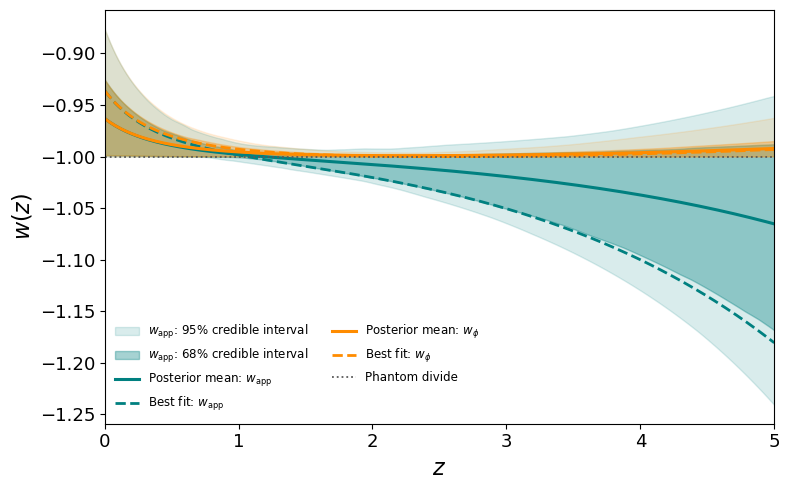

Saved figure: wphi_wapp_reconstruction.pdf
Saved reconstruction table: wphi_wapp_reconstruction.txt


In [5]:
# ============================================================
# 6. PAPER PLOT AND NUMERICAL OUTPUT
# ============================================================
fig, ax = plt.subplots(figsize=(8, 5))

# Apparent EoS
ax.fill_between(
    z_grid,
    low95_wapp,
    high95_wapp,
    color="teal",
    alpha=0.15,
    label=r"$w_{\rm app}$: 95% credible interval",
)
ax.fill_between(
    z_grid,
    low68_wapp,
    high68_wapp,
    color="teal",
    alpha=0.35,
    label=r"$w_{\rm app}$: 68% credible interval",
)
ax.plot(
    z_grid,
    mean_wapp,
    color="teal",
    lw=2.2,
    label=r"Posterior mean: $w_{\rm app}$",
)
ax.plot(
    z_grid,
    bestfit["w_app"],
    color="teal",
    lw=2.0,
    ls="--",
    label=r"Best fit: $w_{\rm app}$",
)

# Intrinsic scalar-field EoS
ax.fill_between(
    z_grid,
    low95_wphi,
    high95_wphi,
    color="darkorange",
    alpha=0.12,
)
ax.fill_between(
    z_grid,
    low68_wphi,
    high68_wphi,
    color="darkorange",
    alpha=0.30,
)
ax.plot(
    z_grid,
    mean_wphi,
    color="darkorange",
    lw=2.2,
    label=r"Posterior mean: $w_\phi$",
)
ax.plot(
    z_grid,
    bestfit["w_phi"],
    color="darkorange",
    lw=2.0,
    ls="--",
    label=r"Best fit: $w_\phi$",
)

ax.axhline(
    -1.0,
    color="0.35",
    lw=1.3,
    ls=":",
    label=r"Phantom divide",
)
ax.set_xlabel(r"$z$", fontsize=16)
ax.set_ylabel(r"$w(z)$", fontsize=16)
ax.set_xlim(Z_MIN, Z_MAX)
if Y_LIMITS is not None:
    ax.set_ylim(*Y_LIMITS)

ax.tick_params(axis="both", labelsize=13)
ax.legend(fontsize=8.5, ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT_PDF, bbox_inches="tight")
plt.show()

output_table = np.column_stack(
    (
        z_grid,
        mean_wapp,
        median_wapp,
        low68_wapp,
        high68_wapp,
        low95_wapp,
        high95_wapp,
        mean_wphi,
        median_wphi,
        low68_wphi,
        high68_wphi,
        low95_wphi,
        high95_wphi,
        bestfit["w_app"],
        bestfit["w_phi"],
        valid_fraction,
    )
)

np.savetxt(
    OUTPUT_DATA,
    output_table,
    header=(
        "z mean_wapp median_wapp low68_wapp high68_wapp "
        "low95_wapp high95_wapp mean_wphi median_wphi "
        "low68_wphi high68_wphi low95_wphi high95_wphi "
        "bestfit_wapp bestfit_wphi valid_posterior_fraction"
    ),
)

print("Saved figure: {}".format(OUTPUT_PDF))
print("Saved reconstruction table: {}".format(OUTPUT_DATA))
